In [1]:
import warnings
warnings.filterwarnings('ignore')
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import association_metrics as am
from sklearn.preprocessing import LabelEncoder
from scipy.stats import rankdata, norm #for Xicor
from datetime import datetime as dt
from sklearn.preprocessing import TargetEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFECV
from sklearn.pipeline import Pipeline

In [10]:
#installs
# !pip install association_metrics

In [934]:
def crosscorr(x, y):
    correlation  = signal.correlate(x, y,'full') 
    lags = signal.correlation_lags(len(x), len(y), mode='full')

    max_corr_lag = lags[np.argmax(correlation)]
    max_corr_value = np.max(correlation)
    cor_tup = (max_corr_lag, max_corr_value)
    return cor_tup

def xicor(x, y, ties="auto"):
    x = np.asarray(x).flatten()
    y = np.asarray(y).flatten()
    n = len(y)

    if len(x) != n:
        raise IndexError(f"x, y length mismatch: {len(x)}, {len(y)}")

    if ties == "auto":
        ties = len(np.unique(y)) < n
    elif not isinstance(ties, bool):
        raise ValueError(f"expected ties either \"auto\" or boolean, got {ties} ({type(ties)}) instead")
    
    y = y[np.argsort(x)]
    r = rankdata(y, method="ordinal")
    nominator = np.sum(np.abs(np.diff(r)))

    if ties:
        l = rankdata(y, method="max")
        denominator = 2 * np.sum(l * (n - l))
        nominator *= n
    else:
        denominator = np.power(n, 2) - 1
        nominator *= 3

    statistic = 1 - nominator / denominator

    return statistic

def feature_selection(X, y, n):
    min_features_to_select = n  
    # cv = TimeSeriesSplit(n_splits=5)
    estimator = RandomForestClassifier(random_state=21)

    rfecv = RFECV(estimator=estimator, min_features_to_select=min_features_to_select, cv=5, scoring = 'accuracy')
    pipeline = Pipeline([
        ('feature_selection', rfecv),
        ('regressor', estimator)
    ])
    pipeline.fit(np.array(X), np.array(y))
    rfecv.fit(np.array(X), np.array(y))
    selected_features = X.columns[rfecv.support_]

    # # Print results
    print(f"Optimal number of features: {rfecv.n_features_}")
    print(f"Selected features: {selected_features.tolist()}")

    # Optionally, plot the cross-validation scores
    plt.figure(figsize=(10, 6))
    plt.plot(range(1, len(rfecv.cv_results_['mean_test_score']) + 1), rfecv.cv_results_['mean_test_score'])
    plt.xlabel('Number of features selected')
    plt.ylabel('Cross-validation score (MSE)')
    plt.title('Recursive Feature Elimination with Cross-Validation')
    plt.show()
    return selected_features.tolist()

In [840]:
def feature_selection(X, y, n):
    min_features_to_select = n  
    cv = TimeSeriesSplit(n_splits=5)
    estimator = RandomForestClassifier(random_state=21)

    rfecv = RFECV(estimator=estimator, min_features_to_select=min_features_to_select, cv=cv, scoring = 'neg_mean_squared_error')
    pipeline = Pipeline([
        ('feature_selection', rfecv),
        ('regressor', estimator)
    ])
    pipeline.fit(np.array(X), np.array(y))
    rfecv.fit(np.array(X), np.array(y))
    selected_features = X.columns[rfecv.support_]

    # # Print results
    print(f"Optimal number of features: {rfecv.n_features_}")
    print(f"Selected features: {selected_features.tolist()}")

    # Optionally, plot the cross-validation scores
    plt.figure(figsize=(10, 6))
    plt.plot(range(1, len(rfecv.cv_results_['mean_test_score']) + 1), rfecv.cv_results_['mean_test_score'])
    plt.xlabel('Number of features selected')
    plt.ylabel('Cross-validation score (MSE)')
    plt.title('Recursive Feature Elimination with Cross-Validation')
    plt.show()
    return selected_features.tolist()

In [728]:
df = pd.read_csv('05_land_river.csv', low_memory = False).replace(np.nan, 0)

## Expolaratory Data Analysis

In [399]:
#make the df for EDA
cols = list(['ecoli_risk', 'date', 'river', 'location', 'catchment_name', 'period'])
cols.extend(df.iloc[:,19:].columns) #extending with all land type columsn
df_eda = df[cols]
df_eda.drop(labels = 'Catchment Area', axis = 1, inplace = True)
df_eda = df_eda[df_eda['catchment_name'] != 0]

### How is land type divided in each catchment

In the below chart we see that land type is not uniformly distributed across catchment areas. Different catchments have different make ups of land type. Some have more land types, while others have fewer in greater proportion. And these proportions vary by catchment too. 

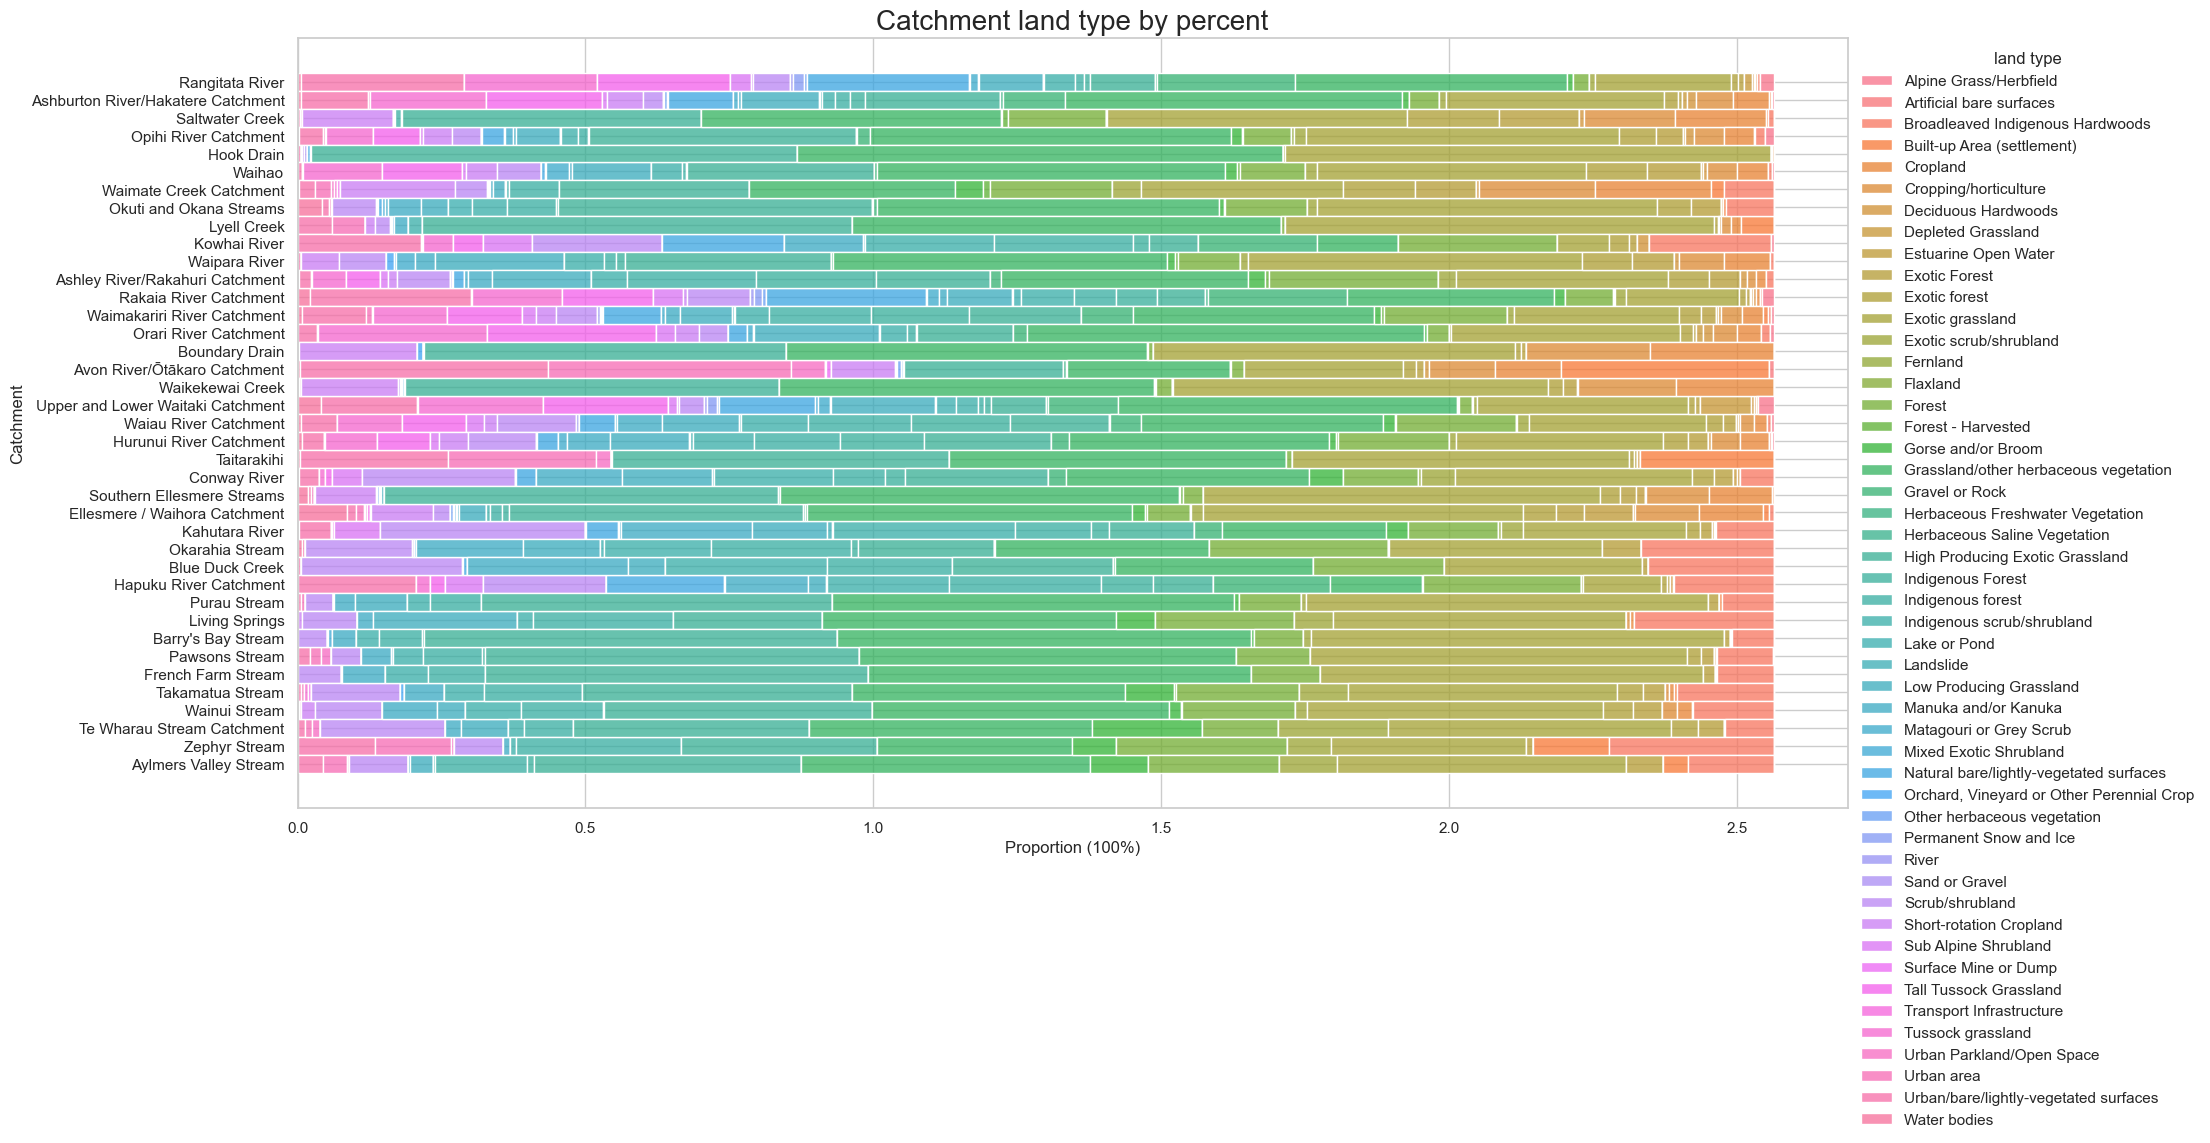

In [408]:
#see how catchment are composed
plot_data = df_eda.drop(labels = ['date', 'river', 'location', 'ecoli_risk', 'period'], axis=1)
plot_data = plot_data.drop_duplicates()
catch = plot_data.catchment_name
plot_data = plot_data.iloc[:,1:].div(plot_data.iloc[:,1:].sum(axis=1), axis=0)
plot_data['catchment'] = catch
plot_data = pd.melt(frame=plot_data, id_vars=["catchment"],)
plot_data.columns = ['catchment', 'land type', 'area']
plot_data['area']= plot_data.groupby('catchment')['area'].transform(lambda x: x / x.sum())

plt.figure(figsize=(20, 10))
ax= sns.histplot(data=plot_data, y='catchment', hue='land type', weights='area', multiple='stack', stat='percent')
plt.xlabel('Proportion (100%)')
plt.ylabel('Catchment')
plt.title('Catchment land type by percent', size = 20)
sns.move_legend(ax, loc="upper left", bbox_to_anchor=(1.0, 1), ncol=1, frameon=False)
plt.show()

### How many samples are there in each catchment, river and location?
Some catchments have more locations sampled than rivers. I.e. rivers with multiple sampling locations. This does not impact the overall number of samples per region.

We also see that each land type has an un-equal number of total samples. As a consequnce of the earlier plot, we know that not all catchments have an equal spread of land types, nor do they have an equal number of samples. Therefore, we want to check that this doesn't impact the way the risk category is represented in the data. i.e. we want to make sure that because alpine grass is samples most, and catchments like the Rangitira river seem to have a lot, that this isn't skewing the way ecoli risk is appearing. One may think more samples will lead to more danger results simply by merit of being sampled more. Assuming everything else is equal and a river is just as likely to have ecoli present as any other (which is not the case, but for EDA purposes we shall check). 

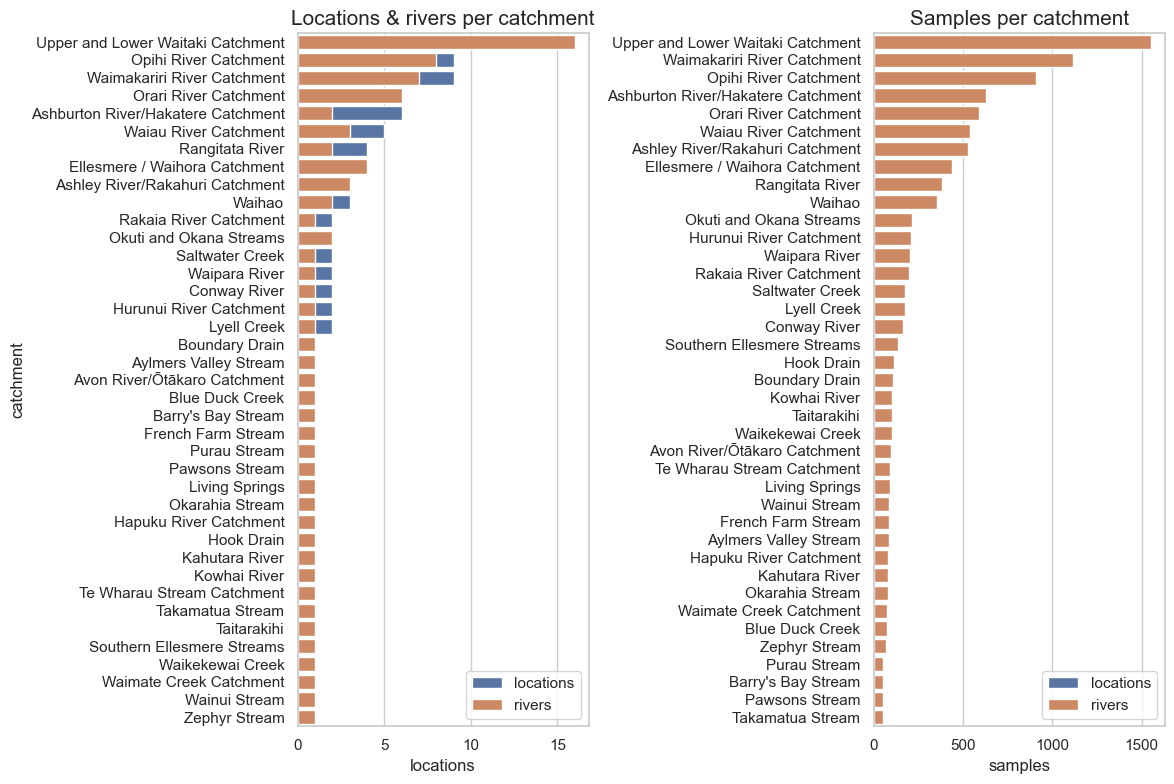

In [402]:
samplesL = df_eda[['catchment_name','location']]
locations = samplesL.drop_duplicates().groupby('catchment_name').size().reset_index()
locations.columns = ['catchment', 'locations']

samplesL = samplesL.groupby('catchment_name').size().reset_index()
samplesL.columns = ['catchment', 'samples']

samplesR = df_eda[['catchment_name','river']]
rivers = samplesR.drop_duplicates().groupby('catchment_name').size().reset_index()
rivers.columns = ['catchment', 'rivers']

samplesR = samplesR.groupby('catchment_name').size().reset_index()
samplesR.columns = ['catchment', 'samples']

fig, axes = plt.subplots(1, 2, figsize=(12, 8))
sns.barplot(y = 'catchment', x = 'locations', data = locations.sort_values(by='locations', ascending=False), label = 'locations', ax=axes[0])
sns.barplot(y = 'catchment', x = 'rivers', data = rivers.sort_values(by='rivers', ascending=False), label = 'rivers', ax=axes[0])
sns.barplot(y = 'catchment', x = 'samples', data = samplesL.sort_values(by='samples', ascending=False), label = 'locations', ax=axes[1])
sns.barplot(y = 'catchment', x = 'samples', data = samplesR.sort_values(by='samples', ascending=False), label = 'rivers', ax=axes[1])
axes[1].set_ylabel("")
axes[0].set_title("Locations & rivers per catchment", size =15)
axes[1].set_title("Samples per catchment", size =15)
axes[0].legend()
axes[1].legend()
plt.tight_layout()
plt.show()

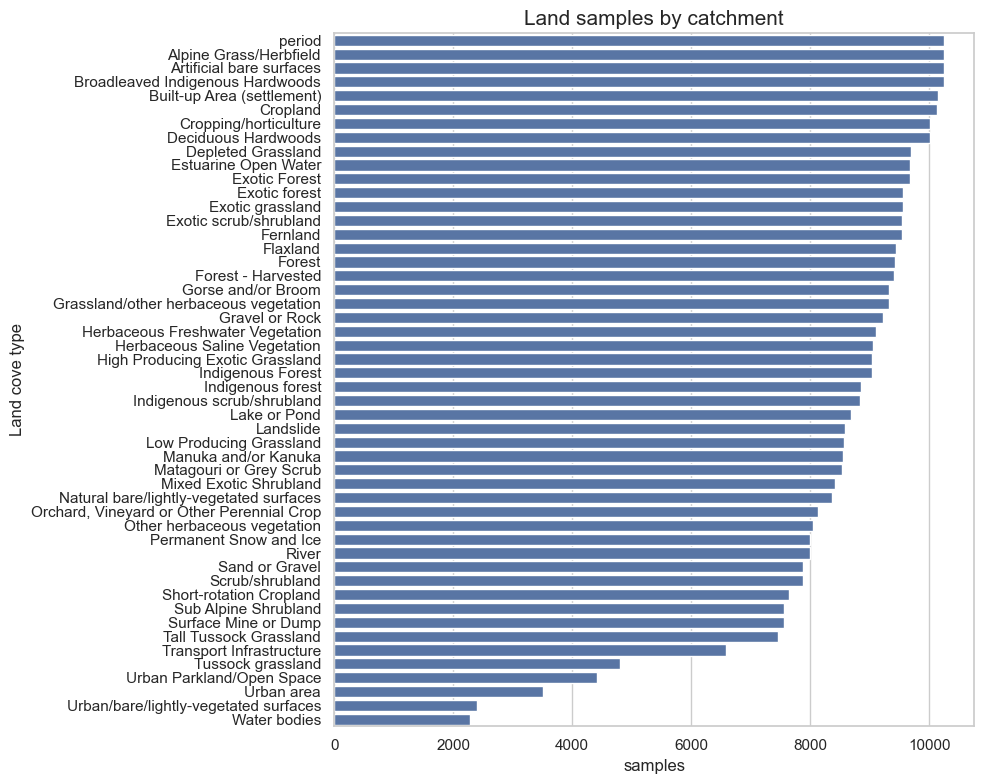

In [405]:
has_land_sample = df_eda.iloc[:,5:].where(df_eda == 0, 1)
has_land_sample = pd.DataFrame(has_land_sample.sum(), columns = ['samples'])

plt.figure(figsize=(10, 8))
sns.barplot(x='samples', y = has_land_sample.index, data = has_land_sample.sort_values(by='samples', ascending=False))
plt.ylabel("Land cove type")
plt.title("Land samples by catchment", size =15)
plt.tight_layout()
plt.show()

### How is Ecoli risk impacted by catchment?
Ecoli risk is not uniform per catchment or land type. With Estaurine Water ways having more danger measurements and places liek Pawson's Barry's aby and Living Springs having more danger measurements. We also see that this varys a lot within each catchment and land type combination. 

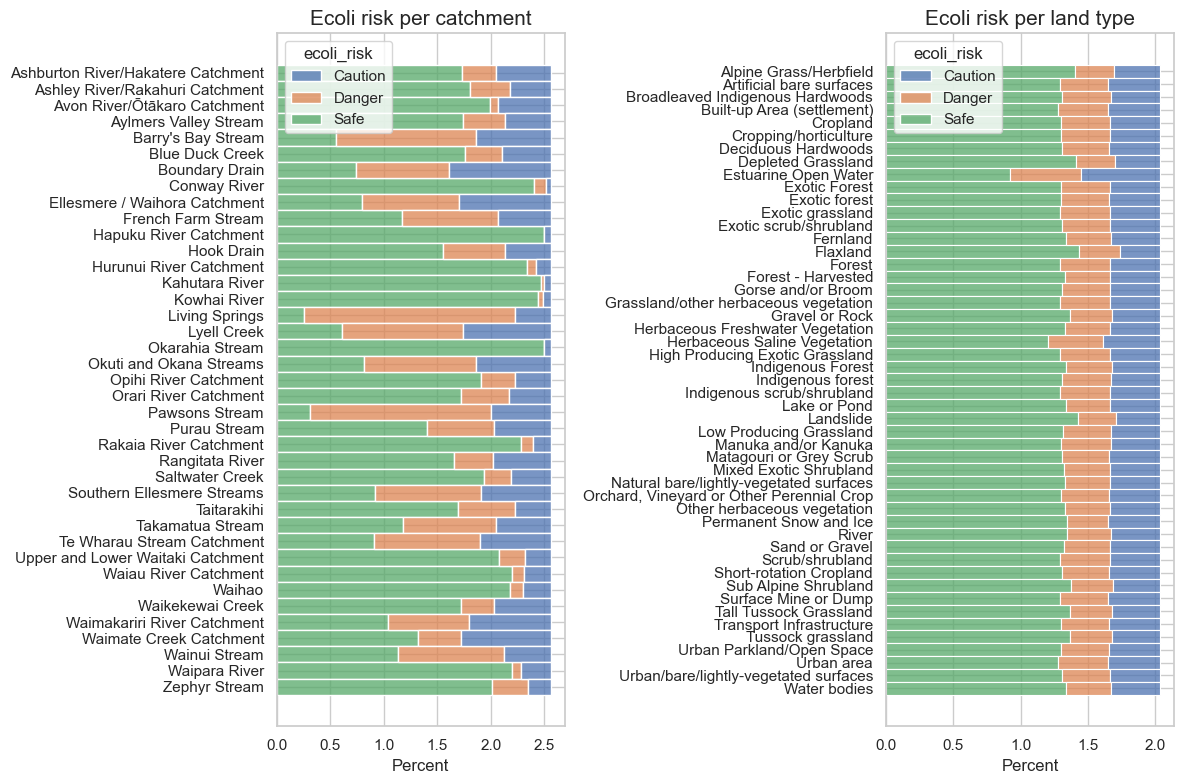

In [543]:
#first how is ecoli risk across catchments
# ecoli = df_eda[['ecoli_risk', 'catchment_name']]
ecoli = pd.crosstab(df_eda['catchment_name'], df_eda['ecoli_risk']).reset_index()
ecoli[['Caution', 'Danger', 'Safe']] = ecoli[['Caution', 'Danger', 'Safe']].div(ecoli[['Caution', 'Danger', 'Safe']].sum(axis=1), axis=0) #divide each row by row sum
ecoli = pd.melt(frame=ecoli, id_vars=["catchment_name"],)

#now ecoli risk by land type
ecoli2 = df_eda.drop(labels = ['location' ,'period'], axis=1)
ecoli2 = pd.melt(frame=ecoli2, id_vars=["catchment_name", 'ecoli_risk', 'date', 'river'],).drop_duplicates()
ecoli2 = ecoli2[(ecoli2 != 0).all(axis=1)] #otherwise each risk level occurs the same number of times, because the catchments all have a value for each land type, because 0 is included. 
ecoli2.drop(labels = ['value'], axis=1, inplace = True)
ecoli3 = pd.crosstab([ecoli2['variable']], ecoli2['ecoli_risk']).reset_index()
ecoli3[['Caution', 'Danger', 'Safe']] = ecoli3[['Caution', 'Danger', 'Safe']].div(ecoli3[['Caution', 'Danger', 'Safe']].sum(axis=1), axis=0)
ecoli3 = pd.melt(frame=ecoli3, id_vars=["variable"],)

fig, axes = plt.subplots(1, 2, figsize=(12, 8))
sns.histplot(data=ecoli, y='catchment_name', hue='ecoli_risk', weights='value', multiple='stack', stat='percent', ax=axes[0])
sns.histplot(data=ecoli3, y='variable', hue='ecoli_risk', weights='value', multiple='stack', stat='percent', ax=axes[1])
axes[0].set_ylabel("")
axes[1].set_ylabel("")
axes[0].set_title("Ecoli risk per catchment", size =15)
axes[1].set_title("Ecoli risk per land type", size =15)
# axes[0].legend()
# axes[1].legend()
plt.tight_layout()
plt.show()

In [544]:
#now ecoli risk by land type
ecoli2 = df_eda.drop(labels = ['location' ,'period'], axis=1)
ecoli2 = pd.melt(frame=ecoli2, id_vars=["catchment_name", 'ecoli_risk', 'date', 'river'],).drop_duplicates()
ecoli2 = ecoli2[(ecoli2 != 0).all(axis=1)] #otherwise each risk level occurs the same number of times, because the catchments all have a value for each land type, because 0 is included. 
ecoli2.drop(labels = ['value'], axis=1, inplace = True)
ecoli2 = pd.crosstab([ecoli2['catchment_name'], ecoli2['variable']], ecoli2['ecoli_risk']).reset_index()
ecoli2[['Caution', 'Danger', 'Safe']] = ecoli2[['Caution', 'Danger', 'Safe']].div(ecoli2[['Caution', 'Danger', 'Safe']].sum(axis=1), axis=0)
ecoli2 = pd.melt(frame=ecoli2, id_vars=["catchment_name", "variable"],)
ecoli2['value']= ecoli2.groupby('catchment_name')['value'].transform(lambda x: x / x.sum())


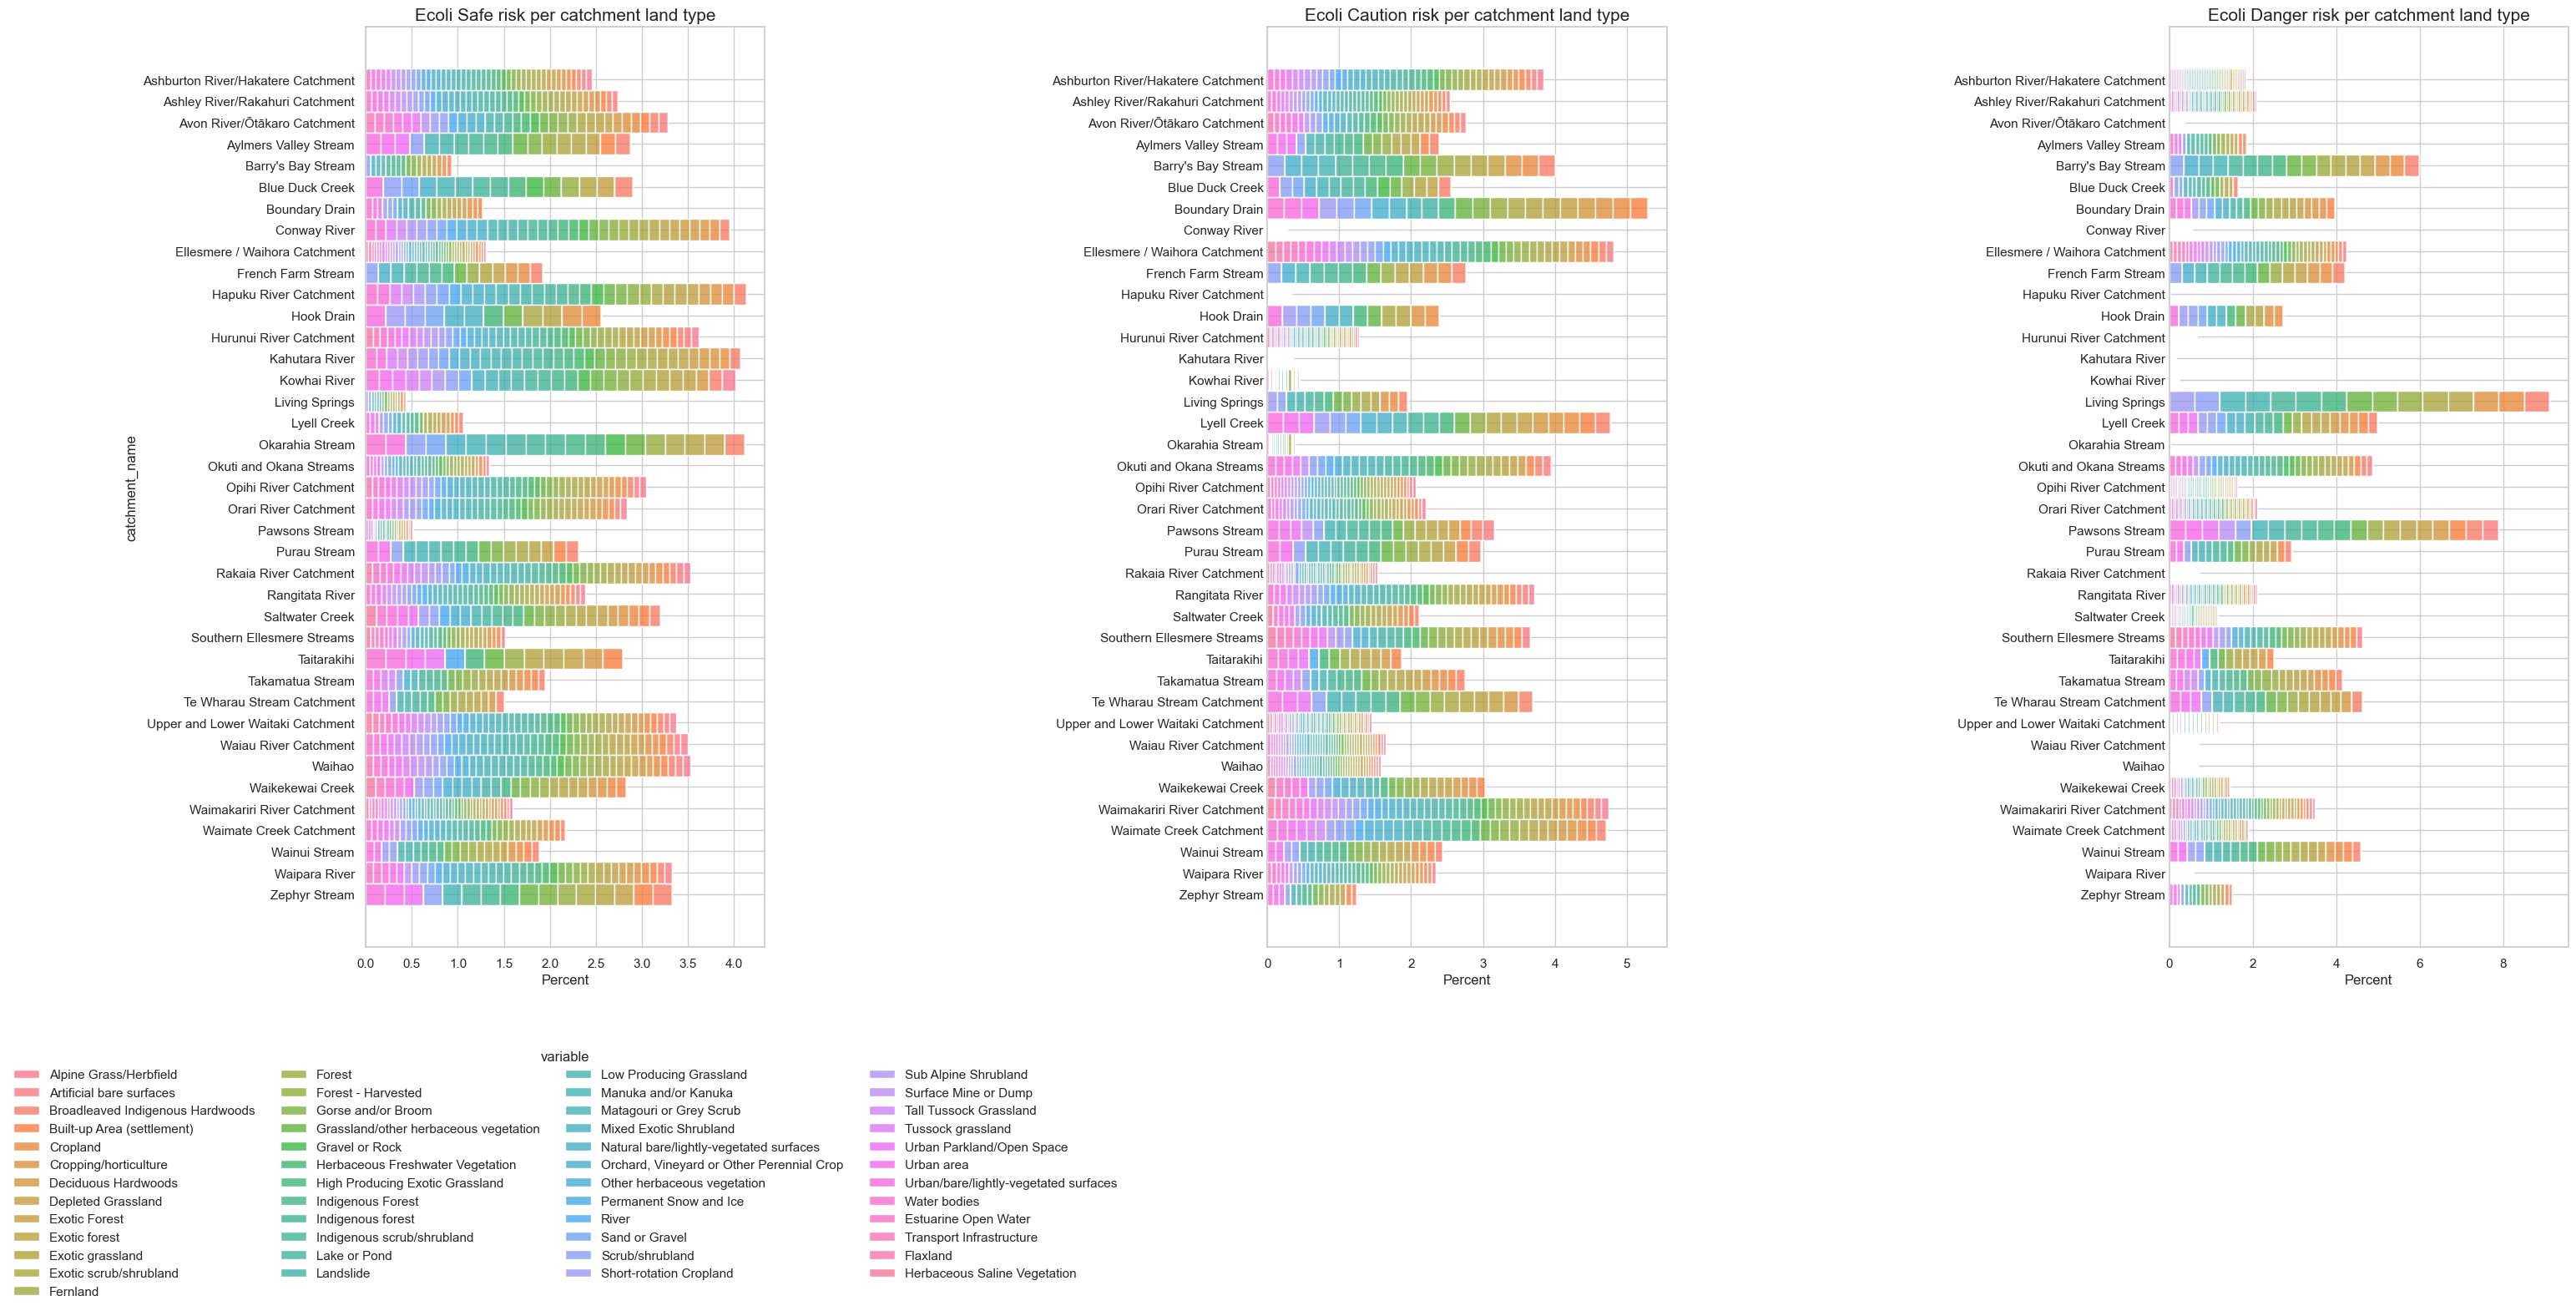

In [576]:
#now ecoli risk by land type
fig, axes = plt.subplots(1, 3, figsize=(30, 16))
ax1= sns.histplot(data=ecoli2.loc[ecoli2['ecoli_risk'] == 'Safe'], y='catchment_name', hue='variable', weights='value', multiple='stack', stat='percent', ax=axes[0])
ax2= sns.histplot(data=ecoli2.loc[ecoli2['ecoli_risk'] == 'Caution'], y='catchment_name', hue='variable', weights='value', multiple='stack', stat='percent', ax=axes[1])
ax3= sns.histplot(data=ecoli2.loc[ecoli2['ecoli_risk'] == 'Danger'], y='catchment_name', hue='variable', weights='value', multiple='stack', stat='percent', ax=axes[2])

sns.move_legend(ax1, loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=4, frameon=False)
axes[1].set_ylabel("")
axes[2].set_ylabel("")
axes[1].tick_params(axis='y', which='both', length=0)
axes[2].tick_params(axis='y', which='both', length=0)

axes[0].set_title("Ecoli Safe risk per catchment land type", size =15)
axes[1].set_title("Ecoli Caution risk per catchment land type", size =15)
axes[2].set_title("Ecoli Danger risk per catchment land type", size =15)

axes[1].legend().remove()
axes[2].legend().remove()

plt.tight_layout()
plt.show()

## How does period affect land type and ecoli risk?
We see that land cover hardly changes over the periods of measurement. Unsurprising. 
However, we do see that over the measurement periods, the number of ecoli risks reported of each category does change. Which is to be expected as the water running through the catchment changes freqeuntly and events that result in ecoli measures changing (which aren't in this dataset) will cause ecoli measures to change. 

In [899]:
#ecoli risk per period and land are per period
#land area per period
period_land = df_eda.drop(labels = ['date', 'river', 'location', 'ecoli_risk'], axis =1)
period_land = pd.melt(frame=period_land, id_vars=["catchment_name", 'period'],).drop_duplicates()
period_land.drop(labels = 'variable', axis = 1, inplace = True)
period_land = period_land.groupby(['catchment_name', 'period'])['value'].sum().reset_index()

#ecoli risk by period
period_ecoli = pd.crosstab([df_eda['catchment_name'], df_eda['period']], df_eda['ecoli_risk']).reset_index()
period_ecoli = pd.melt(frame=period_ecoli, id_vars=["catchment_name", 'period'],).drop_duplicates()

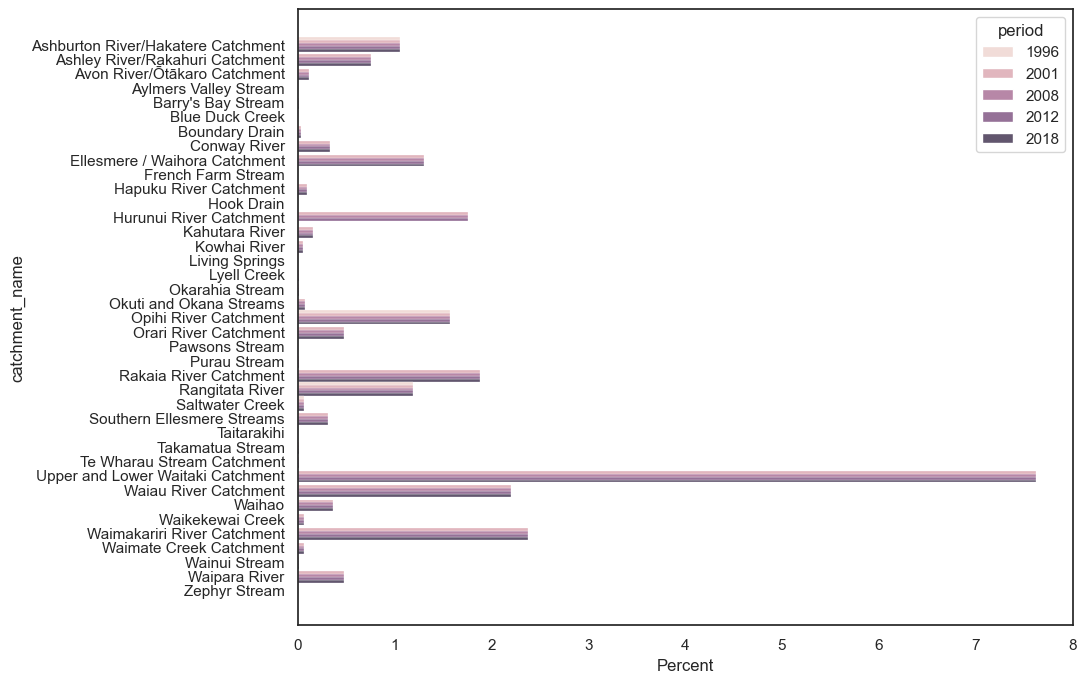

In [876]:
plt.figure(figsize=(10, 8))
sns.histplot(data=period_land, y='catchment_name', hue='period', weights='value', multiple='dodge', stat='percent')
plt.show()

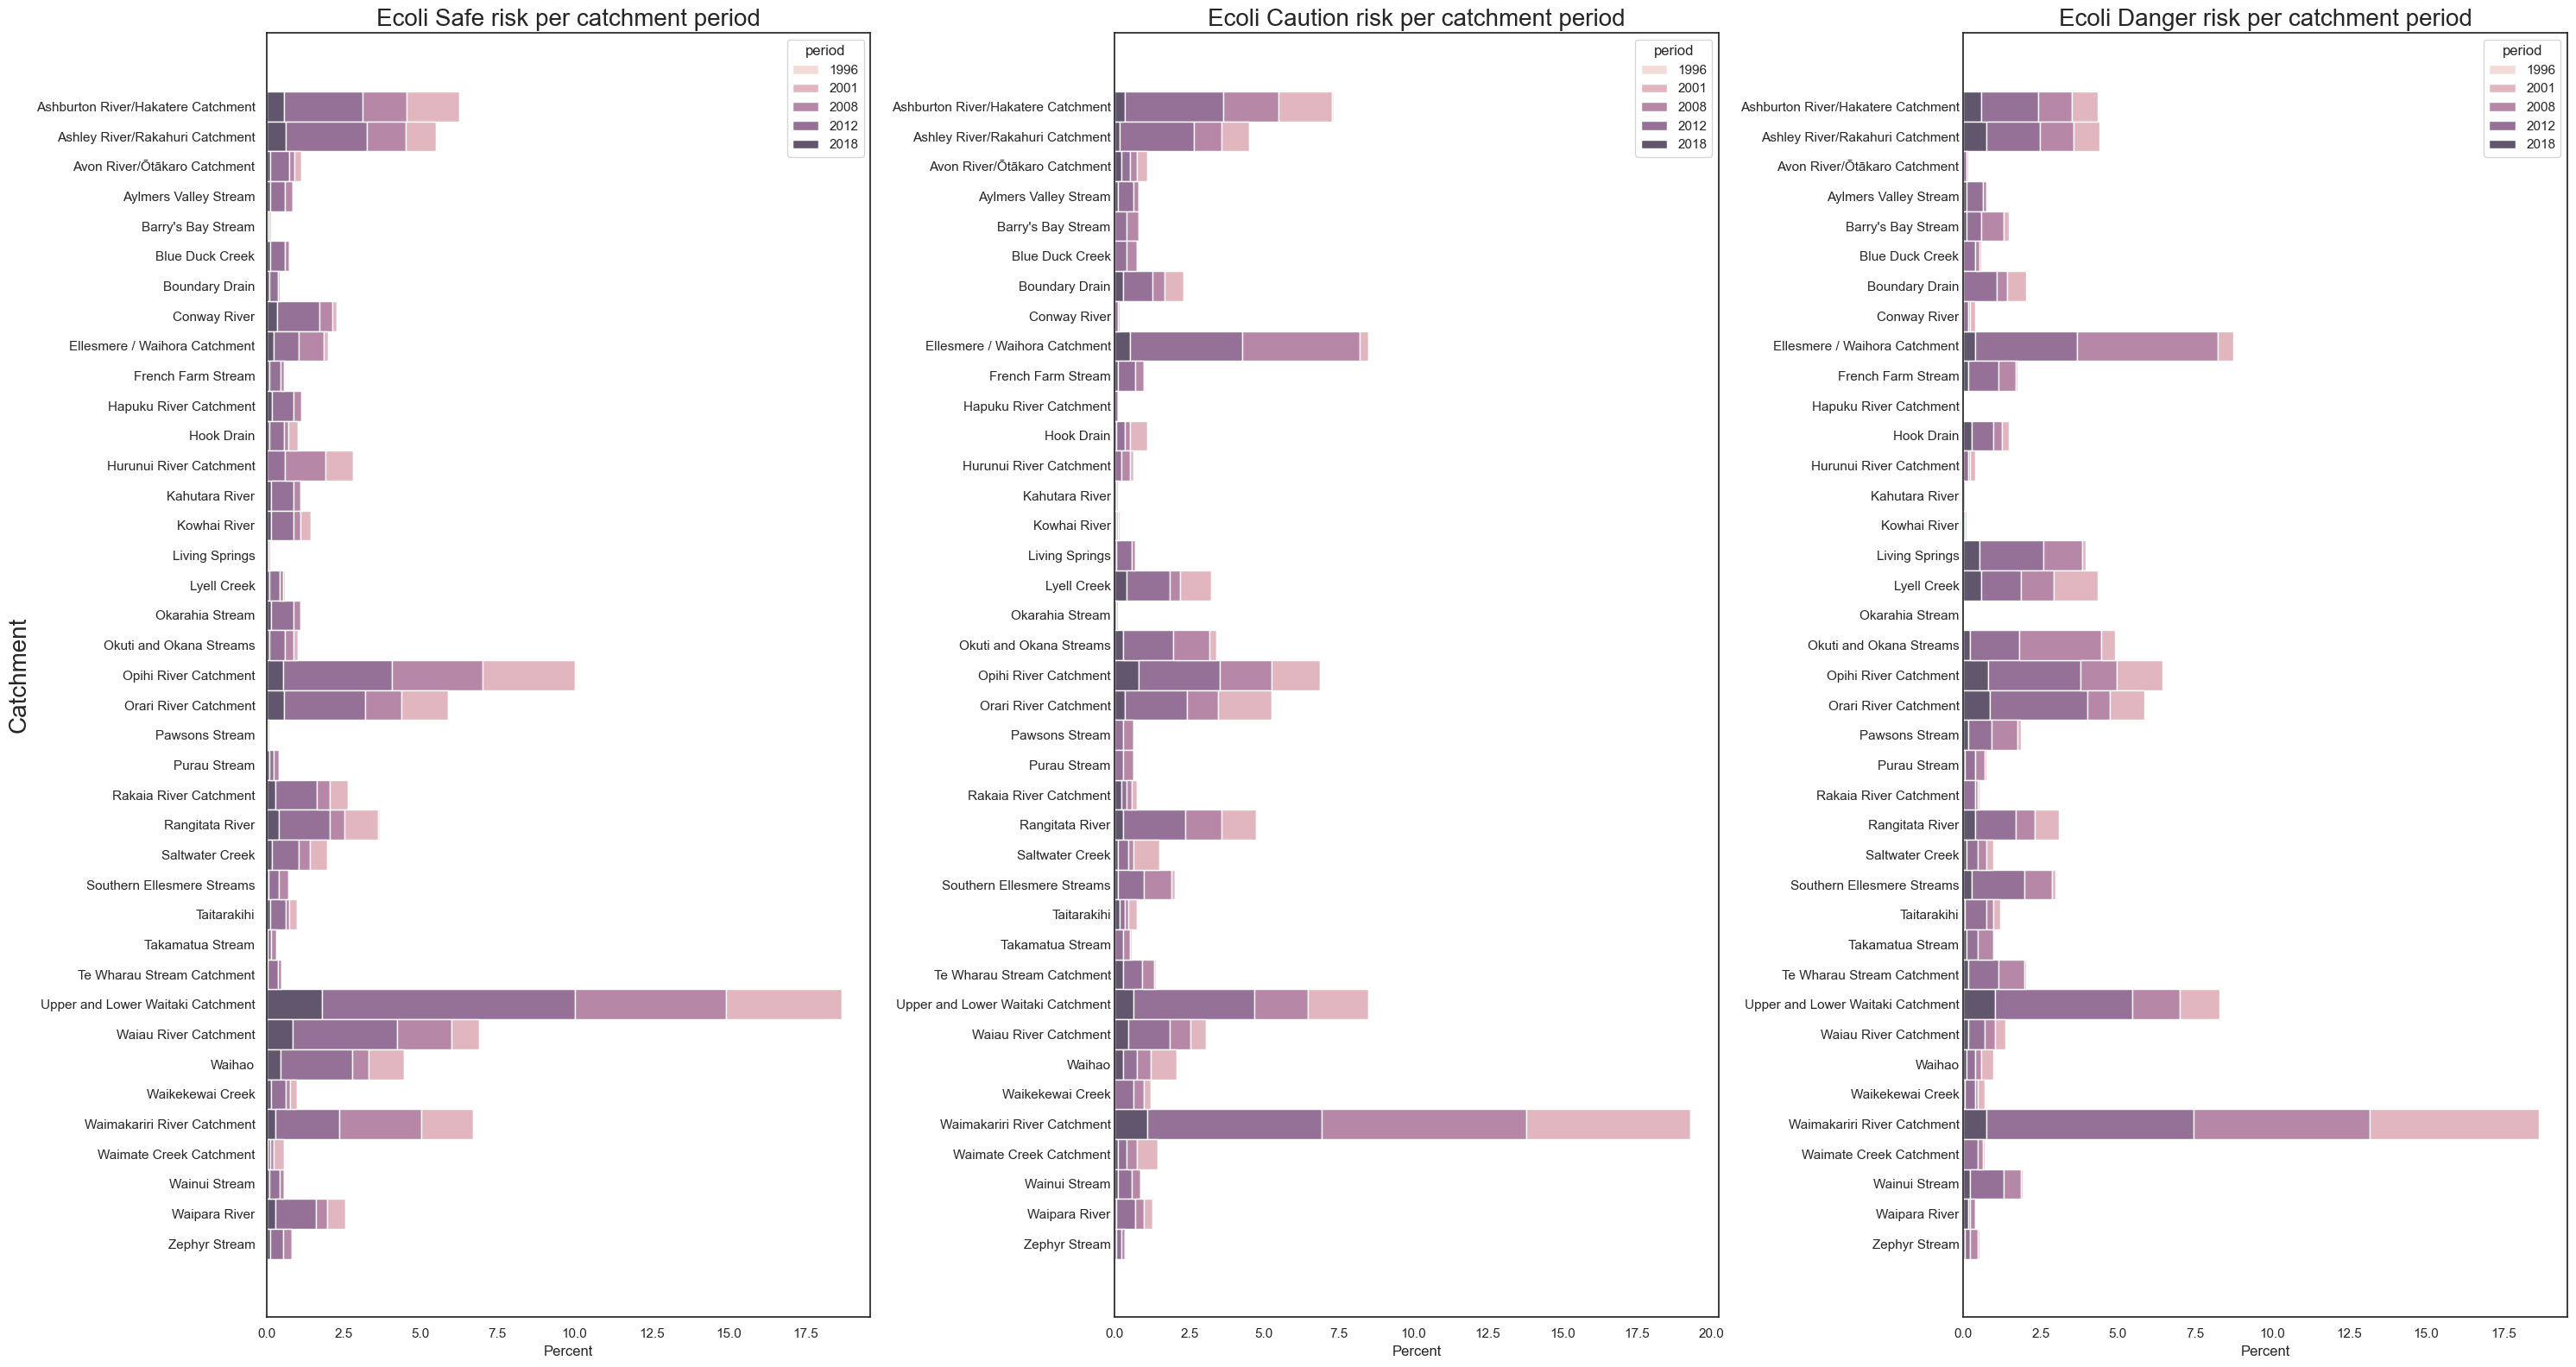

In [901]:
fig, axes = plt.subplots(1, 3, figsize=(30, 16))
ax1 = sns.histplot(data=period_ecoli.loc[period_ecoli['ecoli_risk'] == 'Safe'], y='catchment_name', hue='period', weights='value', multiple='stack', stat='percent', ax = axes[0])
ax2= sns.histplot(data=period_ecoli.loc[period_ecoli['ecoli_risk'] == 'Caution'], y='catchment_name', hue='period', weights='value', multiple='stack', stat='percent', ax = axes[1])
ax3= sns.histplot(data=period_ecoli.loc[period_ecoli['ecoli_risk'] == 'Danger'], y='catchment_name', hue='period', weights='value', multiple='stack', stat='percent', ax = axes[2])
axes[0].set_ylabel("Catchment", size = 20)
axes[1].set_ylabel("")
axes[2].set_ylabel("")
axes[1].tick_params(axis='y', which='both', length=0)
axes[2].tick_params(axis='y', which='both', length=0)

axes[0].set_title("Ecoli Safe risk per catchment period", size =20)
axes[1].set_title("Ecoli Caution risk per catchment period", size =20)
axes[2].set_title("Ecoli Danger risk per catchment period", size =20)

plt.tight_layout()
plt.show()

# Feature Engineering
The area value has a large range across catchments. Above we used the percentage for the EDA to make it easier ot compare between categories. So for the feature engineering we will use percentages of land type within each catchment. And, because datetime can't be used in models directly, we will turn the date column into days since the beginning of measurement. 

In [930]:
#transform each land area into a %
df = df[df['catchment_name'] != 0]
df = df.apply(lambda x: x.astype("category") if x.dtype == "O" else x) #making all non-intetgers into categories for correlatoino later

df_per = df.iloc[:,  19:].drop(labels = 'Catchment Area', axis = 1)
df_per = df_per.div(df_per.sum(axis=1), axis=0)
# df_per = pd.concat([df.iloc[:, 0:19], df_per], axis = 1)
df_per = pd.concat([df.iloc[:, 0], df_per], axis = 1)

#convert date to time for model fitting
start = df['date'][0]
df_per['days'] = pd.to_datetime(df['date'].astype(str))
df_per['days'] = (df_per['days'] - np.datetime64(start)).astype('timedelta64[s]')
df_per['days'] = (df_per['days']/86400).astype('int64') #.dtypes

# Feature Selection
First we will view a heat map of the engineered variables which are continuous. We will use Xi correlation as it doesn't assume linearity and we know that the data aren't linear from our EDA. And a Cramer's correlation martrix for the categorical variables. 

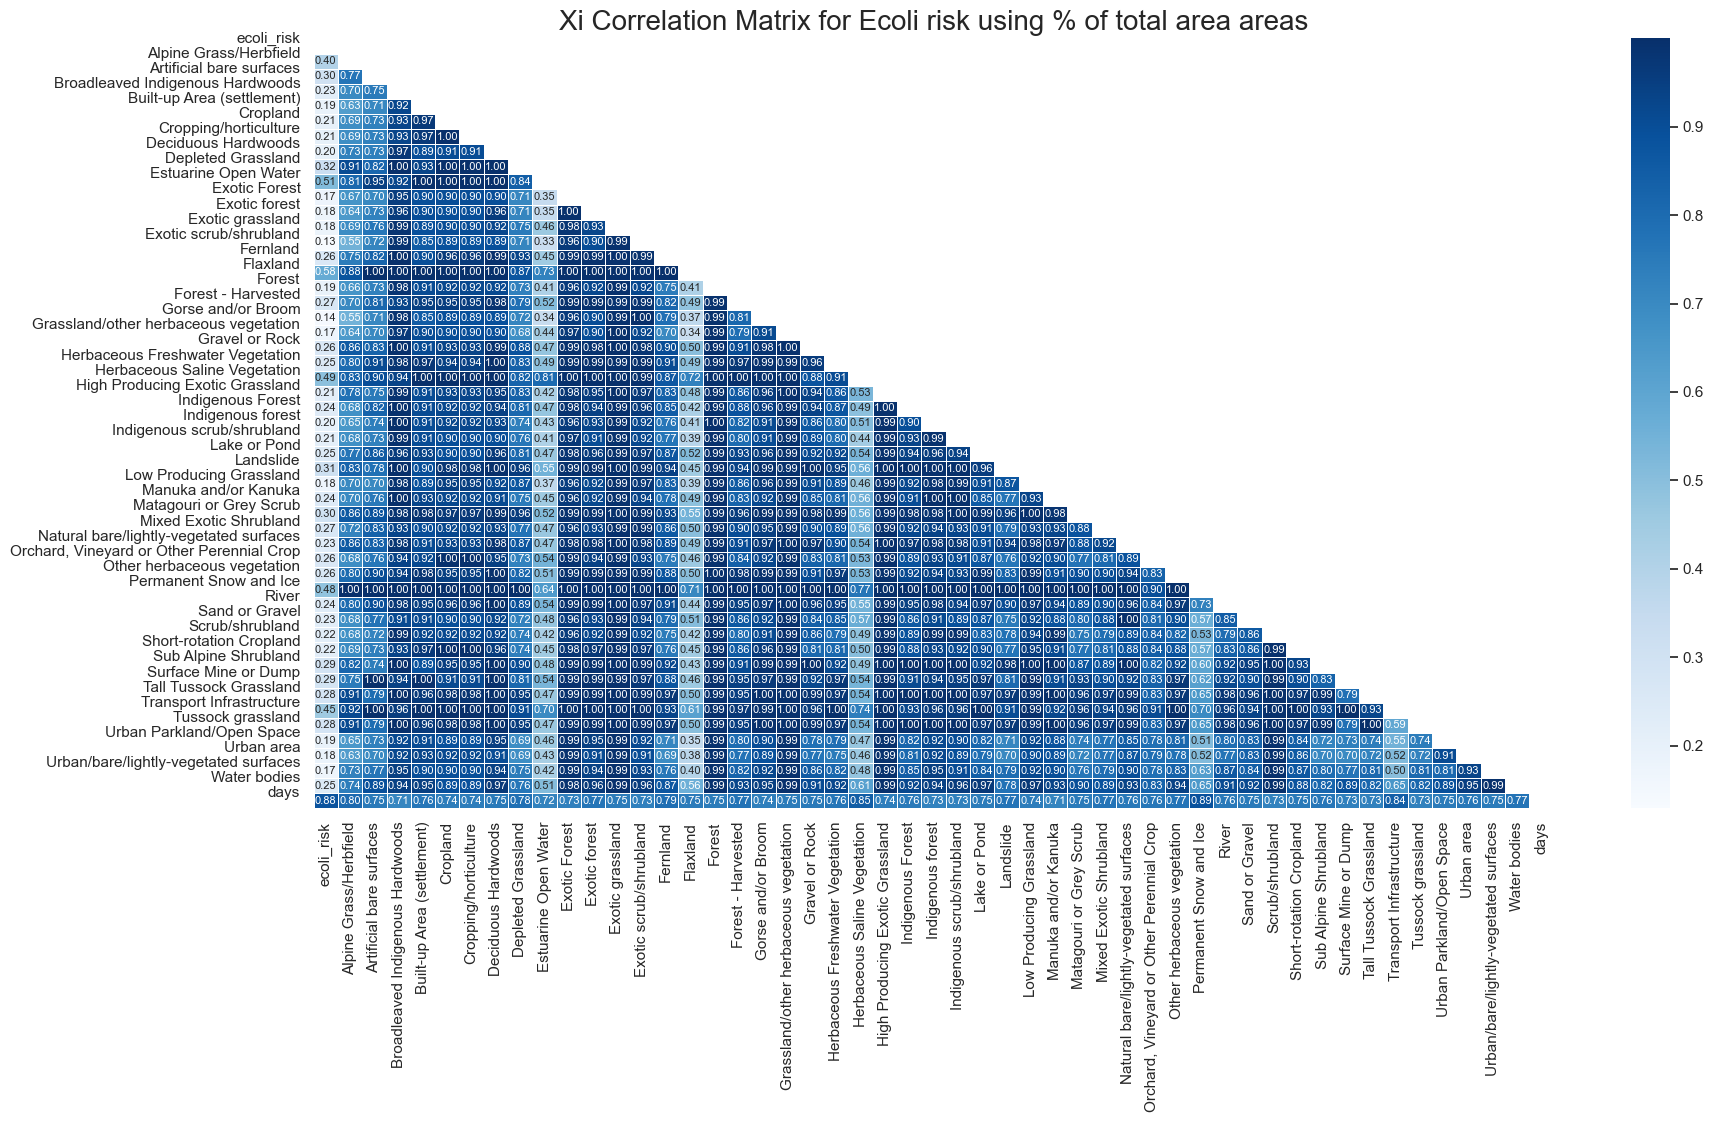

In [808]:
df_per['ecoli_risk'] = label_encoder.fit_transform(df_per['ecoli_risk'])
matrix = df_per.corr(method = xicor) #is_river has such a negative correlation that the color scale is really streched out and all other corrleations appear strong
mask = np.triu(np.ones_like(matrix, dtype=bool))

plt.figure(figsize=(20, 10))
ax = sns.heatmap(matrix, mask = mask, annot=True, cmap='Blues', fmt=".2f", linewidths=0.5, annot_kws={"size": 8})
ax.set_yticks(range(len(matrix)))
ax.set_yticklabels(matrix.index)
plt.title("Xi Correlation Matrix for Ecoli risk using % of total area areas", size = 20)
plt.show()

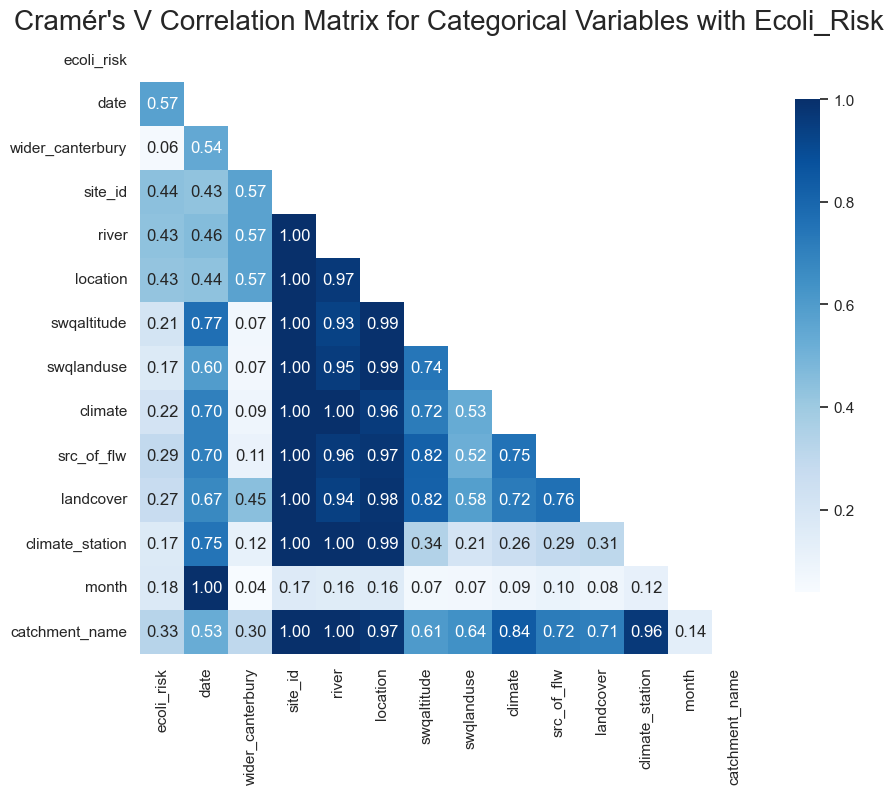

In [809]:
#correlation of categorical features to target ecoli risk
# # Initialize and fit the CramersV object
cramersv = am.CramersV(df)
correlation_matrix = cramersv.fit()

# Display the correlation matrix
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
plt.figure(figsize=(10, 8))
sns.set_style("white")
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="Blues", mask= mask, square=True, cbar_kws={"shrink": .8})
plt.title("Cramér's V Correlation Matrix for Categorical Variables with Ecoli_Risk", size = 20)
plt.show()

In [931]:
#join the two sets of variables with greater than 0.3 correlation
selected_vars_land = list(correlation_matrix[correlation_matrix['ecoli_risk'] >= 0.3].ecoli_risk.drop(labels = ['ecoli_risk']).index) + list(matrix[matrix['ecoli_risk'] >= 0.3].ecoli_risk.drop(labels = ['ecoli_risk']).index)
selected_vars_land.remove('location') #the same as location, seen in EDA
selected_vars_land.remove('river') #highly correalted with site_id

#concatenate all the variables to the engineered data frame
df_per = pd.concat([df.iloc[:, 0:19], df_per], axis = 1)[selected_vars_land]
#get the target variable back
df_selected = pd.concat([df.ecoli_risk, df_per], axis = 1).drop(labels = 'date', axis = 1)

In [932]:
#encode categorical variables for feature selection
model_data = df_selected.copy()
for column in model_data.select_dtypes(include=['category']).columns:
    model_data[column] = label_encoder.fit_transform(model_data[column])

Optimal number of features: 7
Selected features: ['site_id', 'catchment_name', 'Artificial bare surfaces', 'Depleted Grassland', 'Herbaceous Saline Vegetation', 'Landslide', 'days']


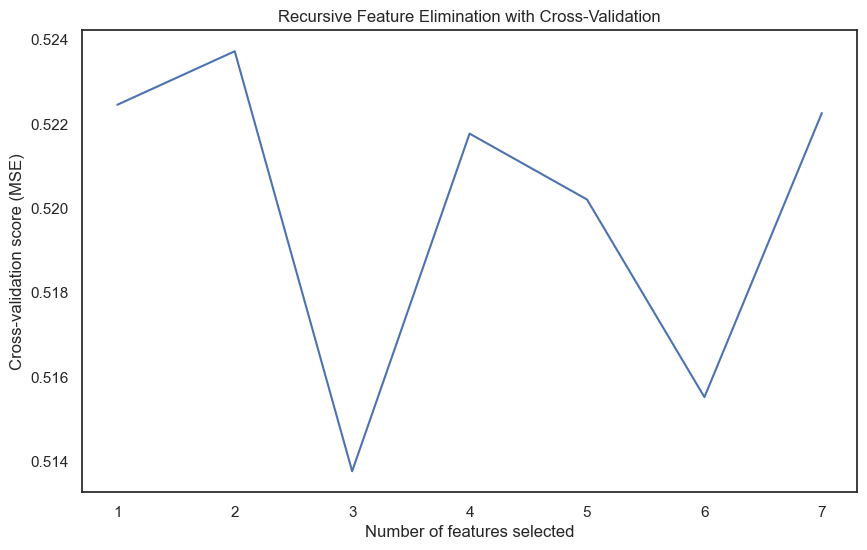

In [938]:
#Note, for RFECV we use encoded variables to avoid selecting dummy variables and resulting in a selected feature set that is full of holes due to the dummies selected. 
selected_features = feature_selection(model_data.iloc[:,1:], model_data.ecoli_risk, 6)

In [918]:
use this code to fit proper models
model_data = df_selected.copy()
model_data['ecoli_risk'] = label_encoder.fit_transform(model_data['ecoli_risk'])

X = model_data.drop('ecoli_risk', axis=1)
y = model_data['ecoli_risk']

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
encoder = TargetEncoder(categories = 'auto', target_type='multiclass', smooth='auto', cv=5, random_state=42)
encoder.fit(X_train, y_train)

# Transform the training and test data
X_train_encoded = encoder.transform(X_train)
X_test_encoded = encoder.transform(X_test)

# # # Train the Random Forest classifier
# # rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
# # rf_classifier.fit(X_train_encoded, y_train)